# Distribution Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 200
df = pd.DataFrame({
    "Age": np.clip(rng.normal(35, 9, n), 18, 65).round().astype(int),
    "Monthly_Spend": rng.lognormal(mean=5.2, sigma=0.65, size=n).round(2),
    "Delivery_Delay": (-rng.exponential(scale=3, size=n)).round(2),
    "Satisfaction": rng.uniform(1, 5, n).round(2)
})
df.loc[0, "Monthly_Spend"] = 3000.0  # intentional unusual value
print(df.head())

   Age  Monthly_Spend  Delivery_Delay  Satisfaction
0   38        3000.00           -1.75          2.86
1   26         452.53           -6.53          4.91
2   42         192.27           -0.65          2.65
3   43         275.49          -11.66          4.17
4   18          47.82           -6.53          1.34


# 1. Normal Distribution
# Definition
A normal distribution is a bell-shaped distribution. Most observations are close to the mean, while fewer appear far from it. It is approximately symmetric, so its mean and median are similar.

# Business Example
Employee heights often cluster near an average with fewer very short or very tall values. A company can use this pattern to understand typical measurements.

# AI/ML Use
Normality can help when interpreting model residuals and statistical tests. Not every ML feature must be normally distributed.

# Python Example

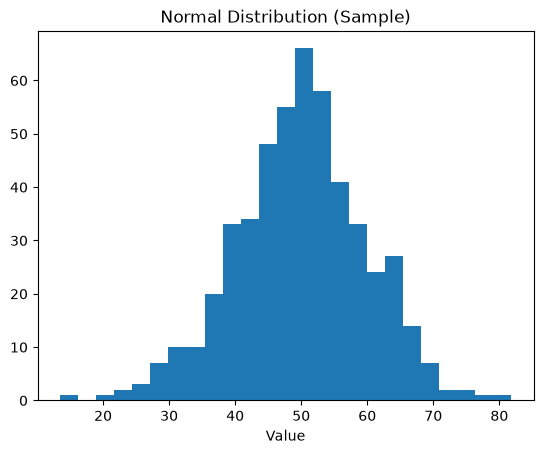

Mean: 49.93 Median: 50.11


In [2]:
values = rng.normal(loc=50, scale=10, size=500)
plt.hist(values, bins=25)
plt.title("Normal Distribution (Sample)")
plt.xlabel("Value")
plt.show()
print("Mean:", round(values.mean(), 2), "Median:", round(np.median(values), 2))

# Explanation
The histogram should be approximately bell-shaped around 50. Its center is near the mean and median. Its spread comes from the standard deviation of about 10. Small asymmetries are expected with random samples.

# 2. Uniform Distribution
Definition
A uniform distribution gives equal likelihood to values across a defined interval. A histogram of many observations often looks relatively flat. It has no single dominant peak.

# Business Example
A retailer might randomly assign a discount percentage within a fixed interval during a simulation. Each allowed value is equally likely in the simulated process.

# AI/ML Use
Uniform samples are useful for random experiments, simulations, and testing pipelines. Real customer data does not automatically follow a uniform distribution.

# Python Example

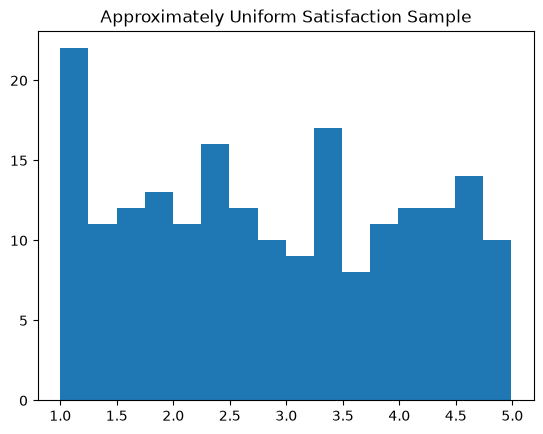

count    200.00000
mean       2.89040
std        1.20372
min        1.00000
25%        1.90000
50%        2.82000
75%        3.95250
max        4.99000
Name: Satisfaction, dtype: float64


In [3]:
plt.hist(df["Satisfaction"], bins=16)
plt.title("Approximately Uniform Satisfaction Sample")
plt.show()
print(df["Satisfaction"].describe())

# Explanation
The simulated Satisfaction values span roughly 1 to 5. The bars should be fairly even rather than concentrated in the middle. The center is near 3 and the spread covers most of the interval.

# 3. Skewness
# Definition
Skewness measures the asymmetry of a numerical distribution. Positive skew indicates a longer right tail; negative skew indicates a longer left tail. Values near zero suggest approximate symmetry, not necessarily normality.

# Business Example
Most customers may spend modest amounts, while a few spend much more. Their spending distribution becomes right-skewed.

# AI/ML Use
Skewness helps identify long-tailed features and possible extreme values. Transformations may help some models, but should be chosen after examining the data.

# Python Example

Age skewness: 0.27
Monthly_Spend skewness: 6.77
Delivery_Delay skewness: -1.71


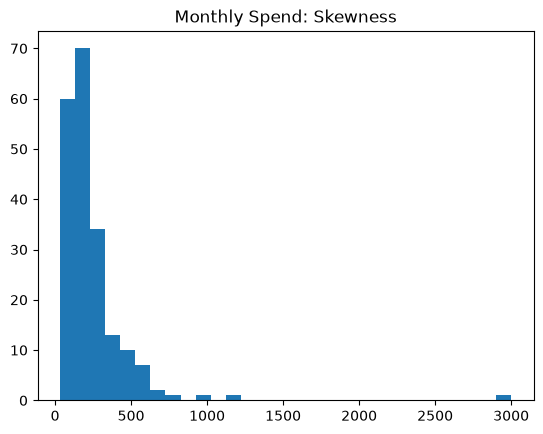

In [4]:
for col in ["Age", "Monthly_Spend", "Delivery_Delay"]:
    print(col, "skewness:", round(df[col].skew(), 2))
plt.hist(df["Monthly_Spend"], bins=30)
plt.title("Monthly Spend: Skewness")
plt.show()

# Explanation
Monthly_Spend is expected to have positive skew due to its long right tail. Delivery_Delay is expected to have negative skew because values extend farther left. Skewness describes shape; it does not by itself prove a data error.

# 4. Kurtosis
Definition
Kurtosis describes the tail heaviness of a distribution relative to a normal distribution. Pandas reports excess kurtosis, where a normal distribution has a theoretical value of zero. High excess kurtosis can signal more extreme observations.

# Business Example
A business may have occasional unusually large transactions. These can make the spending distribution heavy-tailed compared with normal data.

# AI/ML Use
Kurtosis helps highlight tail risk and unusual values that may influence models. It should be interpreted with plots and domain knowledge.

# Python Example


In [5]:
for col in ["Age", "Monthly_Spend", "Satisfaction"]:
    print(col, "excess kurtosis:", round(df[col].kurt(), 2))

Age excess kurtosis: -0.05
Monthly_Spend excess kurtosis: 66.83
Satisfaction excess kurtosis: -1.24


# Explanation
Large positive excess kurtosis suggests relatively heavy tails or extreme values. Values around zero are more normal-like in tail behavior, but do not establish normality. The deliberately high spending observation can strongly affect the result.

# 5. Symmetric Distribution
# Definition
A symmetric distribution has approximately matching shapes on both sides of its center. Its left and right tails are similar in extent. Symmetry does not require a perfect bell shape.

# Business Example
Daily measurement errors around a calibrated target may fall roughly equally above and below the target. This produces an approximately symmetric pattern.

# AI/ML Use
Symmetry makes some summaries, such as the mean, easier to interpret. It can also guide selection of statistical methods and checks on residuals.

# Python Example

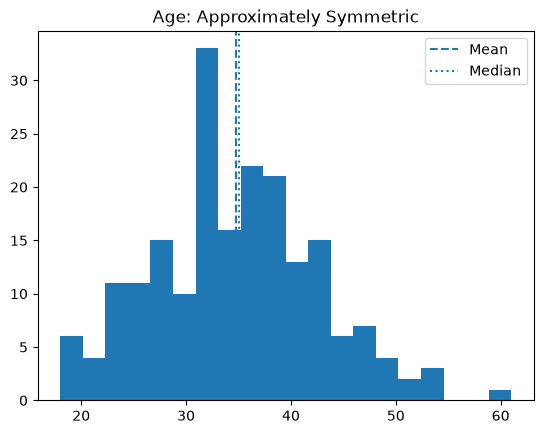

In [6]:
plt.hist(df["Age"], bins=20)
plt.axvline(df["Age"].mean(), linestyle="--", label="Mean")
plt.axvline(df["Age"].median(), linestyle=":", label="Median")
plt.title("Age: Approximately Symmetric")
plt.legend()
plt.show()

# Explanation
Age was simulated from a roughly symmetric distribution, although clipping and rounding can change its shape. Mean and median should be relatively close. The plot shows its center and spread.

# 6. Left-Skewed Distribution
# Definition
A left-skewed distribution has a longer tail toward smaller values. Its skewness is negative. A few unusually low observations pull the tail to the left.

# Business Example
Most deliveries might arrive close to schedule, while a few arrive much earlier than expected. The delivery timing differences can show a left tail.

# AI/ML Use
Left-skewed features may contain unusual low values worth checking. A model may benefit from robust methods if extreme values are influential.

# Python Example

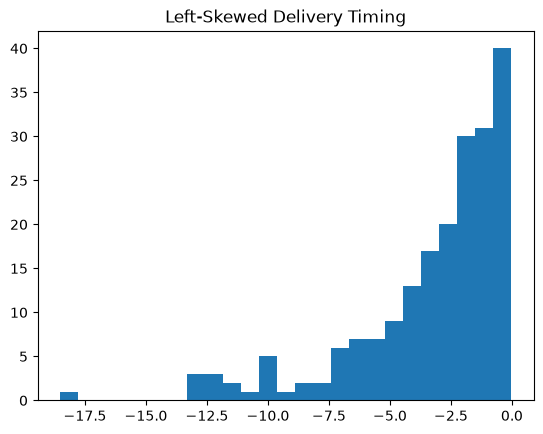

Skewness: -1.71


In [7]:
plt.hist(df["Delivery_Delay"], bins=25)
plt.title("Left-Skewed Delivery Timing")
plt.show()
print("Skewness:", round(df["Delivery_Delay"].skew(), 2))

# Explanation
Delivery_Delay was generated as negative exponential values, producing a longer left tail. Most values lie closer to zero, with fewer far-negative values. These observations are simulated, not automatically errors.

# 7. Right-Skewed Distribution
# Definition
A right-skewed distribution has a longer tail toward larger values. Its skewness is positive. Most observations can be relatively small while a few are very large.

# Business Example
Many customers make small purchases, but a few place expensive orders. Those large purchases extend the spending distribution to the right.

# AI/ML Use
Right-skewed spending may motivate a log transformation for some models. Any transformation should be fitted only on training data to avoid leakage.

# Python Example

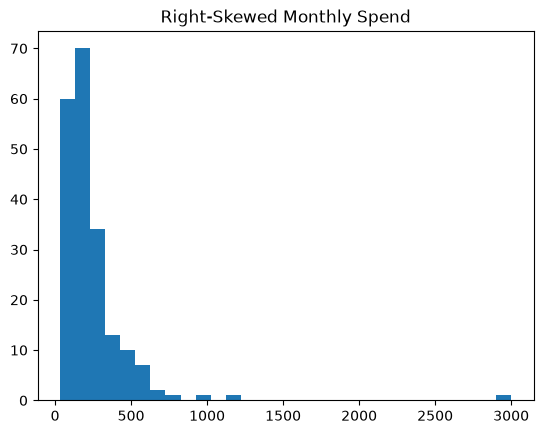

Skewness: 6.77


In [8]:
plt.hist(df["Monthly_Spend"], bins=30)
plt.title("Right-Skewed Monthly Spend")
plt.show()
print("Skewness:", round(df["Monthly_Spend"].skew(), 2))

# Explanation
Most spending observations cluster at lower values, while a long tail extends to high values. The extreme value at 3000 is intentional for practice. It should be investigated before deciding whether to retain or transform it.

# 8. Shape of Distribution
# Definition
The shape of a distribution shows how numerical values are arranged. A distribution can be bell-shaped, nearly flat, symmetric, or skewed. Looking at its shape helps us understand typical values and unusual patterns.

# Business Example
A retail store studies how customer spending is distributed. A histogram can show whether most customers spend similar amounts or whether a few spend much more. The store can use this pattern to understand different purchasing behaviors.

# AI/ML Use
Distribution shape helps an ML engineer decide whether a feature needs transformation. A strongly skewed input may benefit from a log transformation in some models. The shape can also reveal groups of customers or unusual observations.

# Python Example

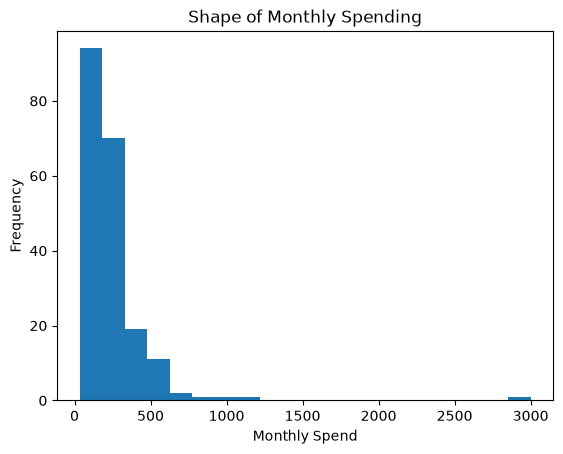

In [10]:
plt.hist(df["Monthly_Spend"], bins=20)
plt.title("Shape of Monthly Spending")
plt.xlabel("Monthly Spend")
plt.ylabel("Frequency")
plt.show()

# Explanation
The histogram shows how often spending values occur in different ranges. Most values are lower, with a tail extending to higher amounts. This is a right-skewed shape, not a symmetric bell curve.

# 9. Center of Distribution
# Definition
The center describes a typical value around which observations are located. Mean gives the arithmetic average, while median gives the middle value after sorting. Comparing mean and median helps explain whether extreme values affect the average.

# Business Example
A company wants to know typical customer spending. It compares average spending with the median bill amount. If a few customers make very large purchases, the mean may be higher than the median.

# AI/ML Use
The center helps summarize feature values before training a model. Mean and median are also common choices for filling missing numerical values. Median is often more robust when a feature contains extreme observations.

# Python Example

In [11]:
s = df["Monthly_Spend"]
print("Mean:", round(s.mean(), 2))
print("Median:", round(s.median(), 2))

Mean: 242.27
Median: 188.54


# Explanation
The mean and median summarize the center of Monthly_Spend. When the mean is greater than the median, a few large values may be pulling the average upward. The median may better describe typical spending in that case.

# 10. Spread of Distribution
# Definition
Spread describes how far numerical values vary around their center. Range is the difference between maximum and minimum values. Standard deviation measures typical variation around the mean, while IQR describes the middle 50% of observations.

# Business Example
An HR team compares employee salaries in two departments. Both departments might have the same average salary but very different salary ranges. Examining spread helps the team understand variation and consistency.

# AI/ML Use
Spread helps determine whether features have very different scales. Scale-sensitive models, such as KNN and regularized linear models, may need standardization. A large spread can also signal potential outliers that need investigation.

# Python Example

In [12]:
s = df["Age"]
print("Range:", round(s.max() - s.min(), 2))
print("Standard Deviation:", round(s.std(), 2))
print("IQR:", round(s.quantile(0.75) - s.quantile(0.25), 2))

Range: 43
Standard Deviation: 7.91
IQR: 11.0


# Explanation
Range describes the total span of ages. Standard deviation shows how much ages vary around the mean. IQR focuses on the middle half of ages and is less affected by extreme values.

# 11. Skewness Analysis
# Definition
Skewness measures whether a numerical distribution has a longer tail on one side. Positive skew means the tail extends toward larger values. Negative skew means the tail extends toward smaller values, while values near zero suggest approximate symmetry.

# Business Example
An online store finds that most customers spend modest amounts, but a few spend much more. This creates positive skew in purchase amounts. Understanding the skew helps the store report customer behavior accurately.

# AI/ML Use
Skewness can guide feature preprocessing for ML models. Strongly skewed positive features may be candidates for a log transformation if their values allow it. The transformation should be checked against model performance rather than applied automatically.

# Python Example

In [13]:
for col in ["Age", "Monthly_Spend", "Delivery_Delay"]:
    print(col, "skewness:", round(df[col].skew(), 2))

Age skewness: 0.27
Monthly_Spend skewness: 6.77
Delivery_Delay skewness: -1.71


# Explanation
Positive skewness indicates a longer right tail, and negative skewness indicates a longer left tail. Monthly_Spend is expected to be positively skewed, while Delivery_Delay is expected to be negatively skewed. Skewness is a description of shape, not proof that values are incorrect.

# 12. Presence of Outliers
# Definition
Outliers are observations that are unusually far from most other values. They may be genuine, caused by measurement errors, or caused by incorrect data entry. The IQR method flags values outside the usual lower and upper fences for further inspection.

# Business Example
A shop records an unusually large customer order. It could be a genuine bulk purchase or a mistaken amount entered by staff. The shop should verify the transaction before deciding whether to change the record.

# AI/ML Use
Outliers may affect model training, summary statistics, and feature scaling. Some models are sensitive to extreme values, while tree-based models are often less sensitive. Outliers should be investigated and not automatically deleted.

# Python Example

In [14]:
s = df["Monthly_Spend"]
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[(s < lower) | (s > upper)]
print("Potential outliers:", len(outliers))
print(outliers[["Monthly_Spend"]].head())

Potential outliers: 13
    Monthly_Spend
0         3000.00
26         931.09
27         613.97
44         723.43
47         598.24


# Explanation
The IQR rule flags spending amounts outside the calculated fences. These are potential outliers, not confirmed errors. Investigate the high spending values before deciding to retain, transform, correct, or remove them.